# Multiband Speech ABR: grand average

Loads every `*_MultibandABR.npz` in the results folder and plots mean ± SEM across subjects.

4 subjects: ['AT', 'EA', 'HB', 'SUB']


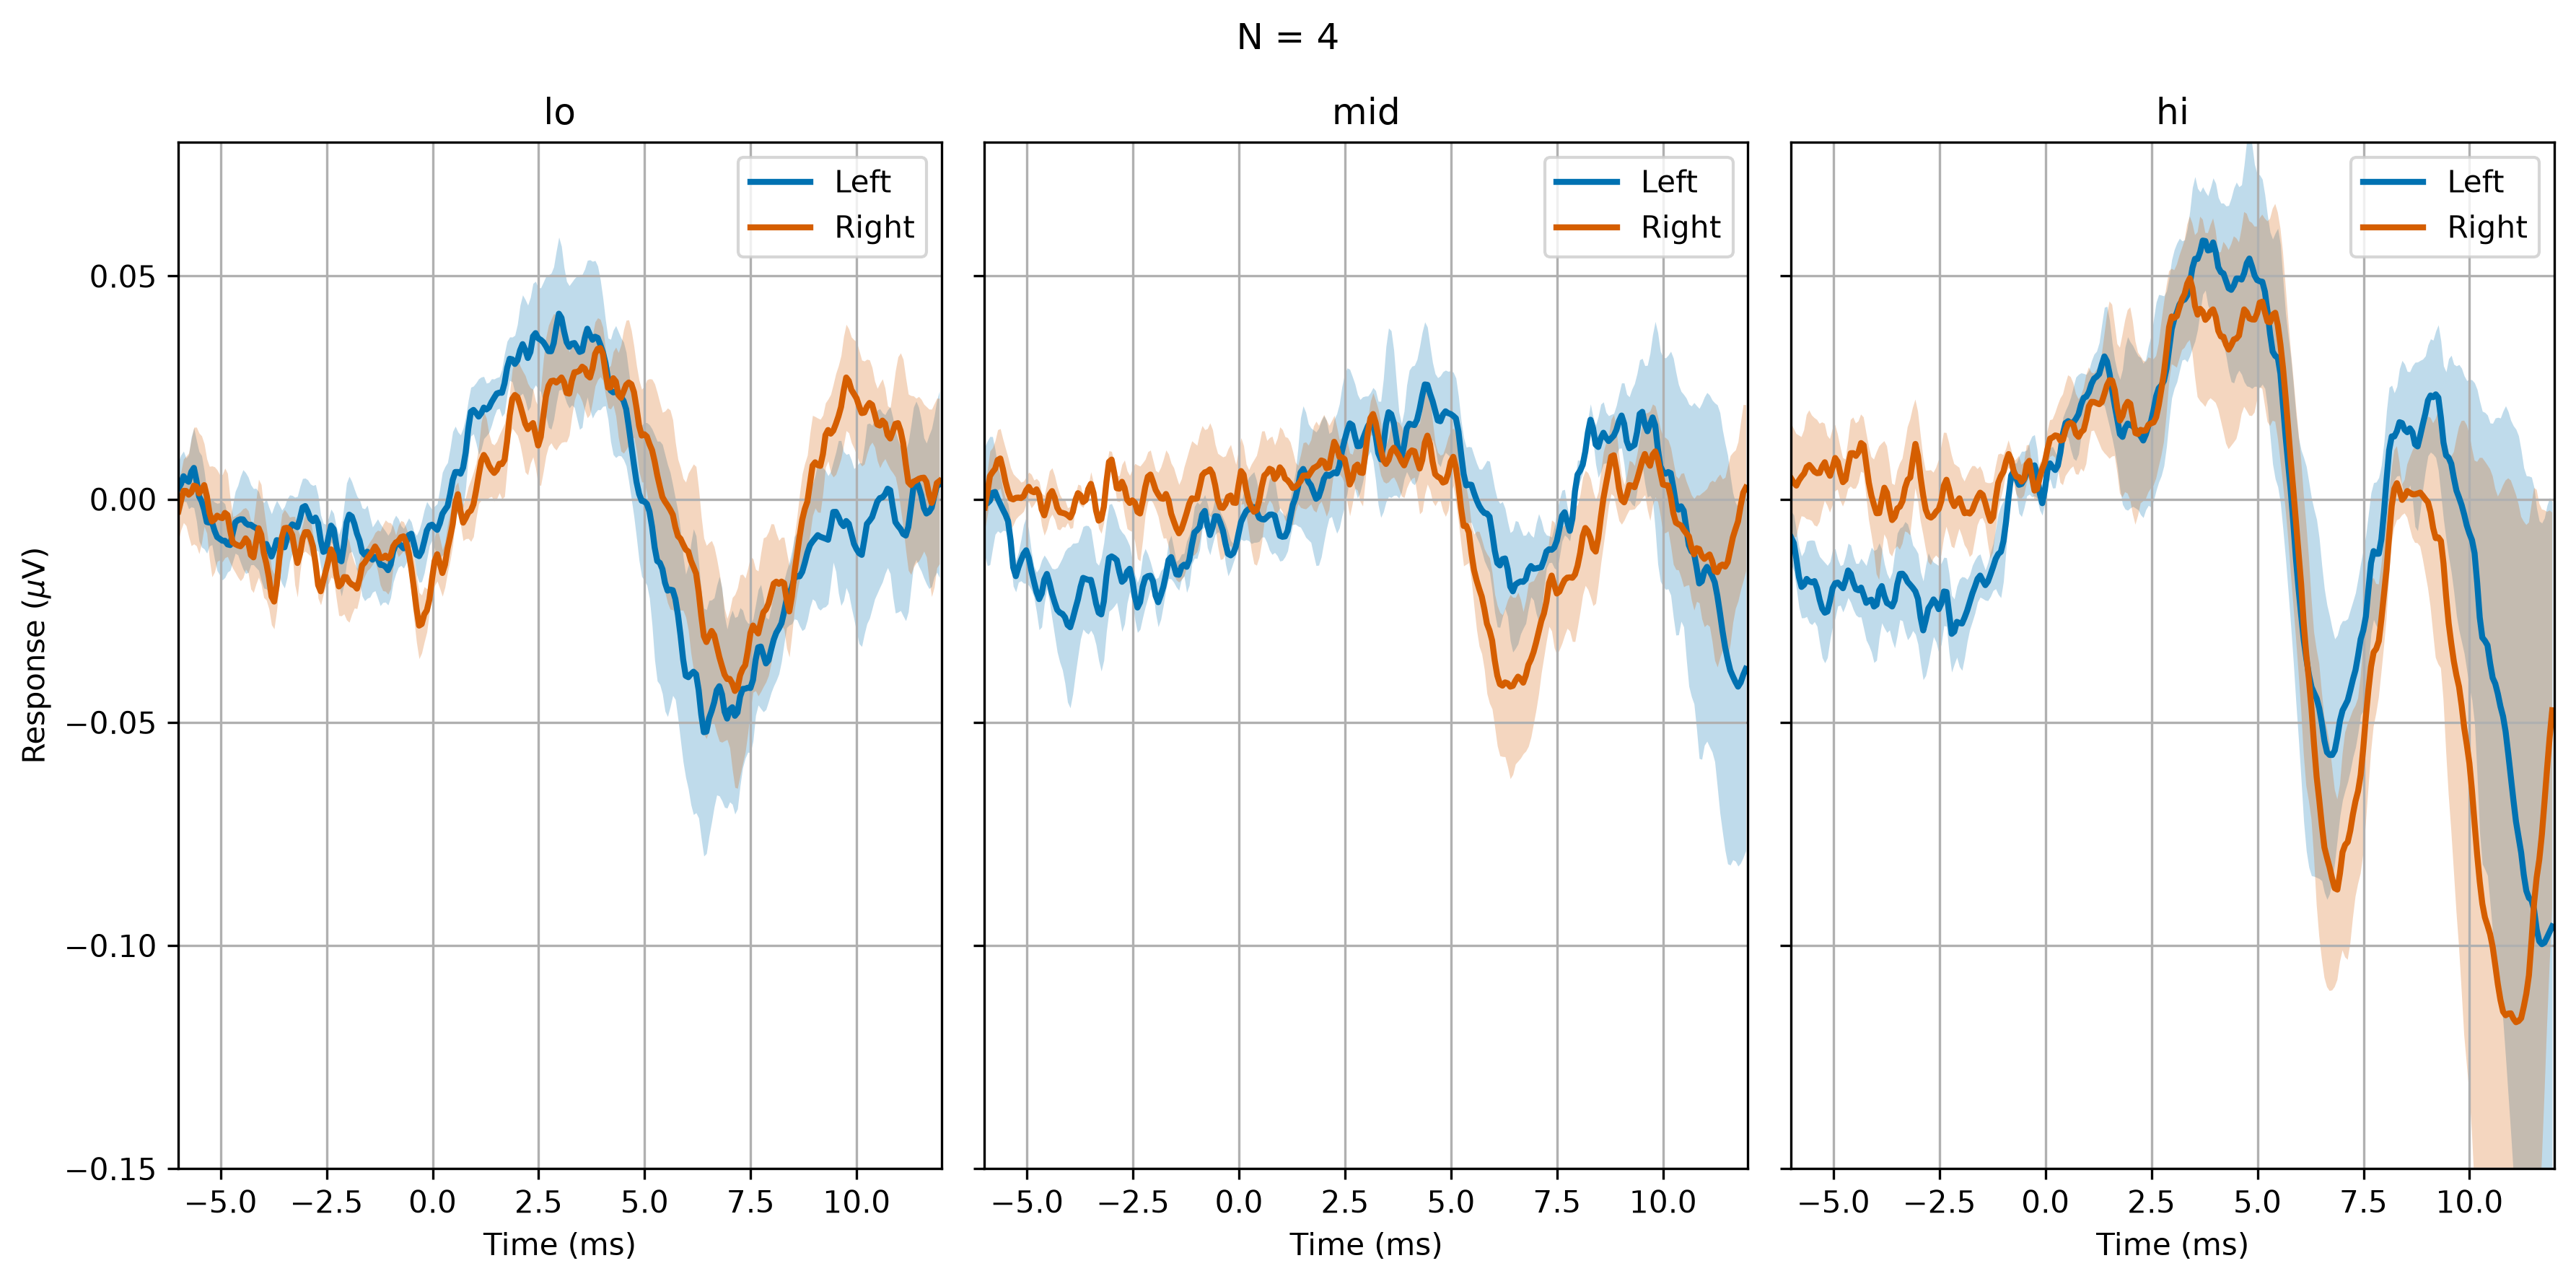

In [1]:
import numpy as np
import os
import glob
import pylab as pl

froot = '/Users/HMB105/Dropbox/Data_Testing/MultibandPeakySpeech/'
res_dir = froot + 'Results/'
exclude_subjs = []          # subject IDs to leave out, e.g. ['AT']
plot_win = (-6., 12.)         # ms, delay-corrected axis

# Load and stack (all files are assumed to share the same time axis and settings)
Z = [np.load(f) for f in sorted(glob.glob(os.path.join(res_dir, '*_MultibandABR.npz')))]
Z = [z for z in Z if str(z['subj']) not in exclude_subjs]
N = len(Z)
t_ms = Z[0]['t_ms']
sets = [str(s) for s in Z[0]['sets']]
R = np.array([z['resp'] for z in Z])                  # (N, 6, n_time), uV
mean, sem = R.mean(axis=0), R.std(axis=0, ddof=1) / np.sqrt(N)
print(N, 'subjects:', [str(z['subj']) for z in Z])

# Plot: one column per band, Left (blue) and Right (red) overlaid
blue, red = '#0072B2', '#D55E00'
w = (t_ms >= plot_win[0]) & (t_ms <= plot_win[1])
fig, axs = pl.subplots(1, 3, figsize=(12, 6), sharex=True, sharey=True, dpi=300)
for ax, b in zip(axs, ['lo', 'mid', 'hi']):
    for ear, col, lab in [('L', blue, 'Left'), ('R', red, 'Right')]:
        i = sets.index(ear + b)
        ax.fill_between(t_ms[w], (mean[i] - sem[i])[w], (mean[i] + sem[i])[w], color=col, alpha=0.25, lw=0)
        ax.plot(t_ms[w], mean[i][w], color=col, lw=2, label=lab)
        # ax.plot(t_ms[w], R[:, i, w].T, color=col, lw=0.5, alpha=0.3)
    ax.set_title(b); ax.set_xlabel('Time (ms)'); ax.grid(); ax.legend(loc='upper right')
axs[0].set_ylabel(r'Response ($\mu$V)')
axs[0].set_xlim(*plot_win)
axs[0].set_ylim((-0.15, 0.08))
pl.suptitle(f'N = {N}')
pl.tight_layout()